# Khám phá dữ liệu sinh viên — Student Dropout
## 1. Đọc dữ liệu và kiểm tra cấu trúc ban đầu

### Mục đích
Đọc dữ liệu CSV, xác định kích thước và quan sát một số bản ghi đầu tiên.

### Cách thực hiện và lý do
- Dùng đường dẫn dựa trên thư mục dự án để thuận tiện chạy trên máy thành viên.
- Dùng dấu phân cách `;` theo định dạng file dữ liệu.
- Hiển thị 5 dòng đầu để kiểm tra các cột đã được tách đúng.

In [13]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
import pandas as pd

# Tìm thư mục dự án khi chạy từ thư mục gốc hoặc notebooks
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_path = project_dir / "data" / "raw" / "student_dropout.csv"

df = pd.read_csv(data_path, sep=";")

print("Số dòng, số cột:", df.shape)
display(df.head())

Số dòng, số cột: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### Nhận xét
- Đã đọc thành công dữ liệu gồm 4.424 dòng và 37 cột.
- Trong đó có 36 đặc trưng đầu vào và một biến mục tiêu `Target`.
- Các cột được tách riêng, cho thấy dấu phân cách đang sử dụng phù hợp.
- Chưa thay đổi hoặc loại bỏ bản ghi ở bước này.

## 2. Kiểm tra chất lượng dữ liệu và phân bố biến mục tiêu

### Mục đích
Kiểm tra kiểu dữ liệu, giá trị thiếu, dòng trùng và số lượng mẫu của từng lớp.

### Cách thực hiện và lý do
- `info()`: kiểm tra kiểu dữ liệu và số giá trị khác null.
- `isna()`: xác định có cần xử lý giá trị thiếu hay không.
- `duplicated()`: phát hiện các dòng trùng hoàn toàn.
- `value_counts()`: xác định phân bố ba lớp của biến mục tiêu.

Lưu ý: Một thuộc tính có kiểu số vẫn có thể biểu diễn mã danh mục,
chẳng hạn mã ngành học. Cần xem ý nghĩa biến trước khi chọn cách encoding.

In [20]:
# 1. Kiểm tra tên cột và kiểu dữ liệu
print("=== THÔNG TIN DỮ LIỆU ===")
df.info()

# 2. Kiểm tra giá trị thiếu
print("\n=== GIÁ TRỊ THIẾU ===")
missing = df.isna().sum()
print(missing[missing > 0])
print("Tổng giá trị thiếu:", missing.sum())

# 3. Kiểm tra dòng trùng hoàn toàn
print("\n=== DÒNG TRÙNG ===")
print("Số dòng trùng:", df.duplicated().sum())

# 4. Kiểm tra số lượng và tỷ lệ của từng lớp
print("\n=== PHÂN BỐ TARGET ===")
target_summary = pd.DataFrame({
    "Số lượng": df["Target"].value_counts(),
    "Tỷ lệ (%)": df["Target"].value_counts(normalize=True).mul(100).round(2)
})
display(target_summary)

=== THÔNG TIN DỮ LIỆU ===
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification    

,Số lượng,Tỷ lệ (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


### 2.1. Tổng hợp kết quả kiểm tra

Output của bước trước bị thu gọn do dài. Cell dưới đây hiển thị lại
các thông tin chính để thuận tiện kiểm chứng và ghi vào báo cáo.
Đây là bước tổng hợp, không thực hiện thêm thao tác xử lý dữ liệu.

In [21]:
print("Số mẫu:", len(df))
print("Số đặc trưng:", df.drop(columns="Target").shape[1])
print("Tổng giá trị thiếu:", df.isna().sum().sum())
print("Số dòng trùng:", df.duplicated().sum())
print("Các nhãn:", df["Target"].unique())

Số mẫu: 4424
Số đặc trưng: 36
Tổng giá trị thiếu: 0
Số dòng trùng: 0
Các nhãn: <StringArray>
['Dropout', 'Graduate', 'Enrolled']
Length: 3, dtype: str


### Nhận xét và quyết định xử lý

- Dataset có 4.424 mẫu, 36 đặc trưng và một biến mục tiêu.
- Không phát hiện giá trị thiếu bằng `isna()`, nên hiện chưa cần điền thiếu.
- Không phát hiện dòng trùng hoàn toàn, nên chưa cần loại dòng trùng.
- Biến mục tiêu có ba lớp:

| Lớp | Số lượng | Tỷ lệ |
|---|---:|---:|
| Graduate | 2.209 | 49,93% |
| Dropout | 1.421 | 32,12% |
| Enrolled | 794 | 17,95% |

- Số mẫu giữa các lớp chênh lệch; Graduate nhiều nhất, Enrolled ít nhất.
- Khi chia dữ liệu, nhóm dự kiến giữ tỷ lệ lớp bằng stratification.
- Khi đánh giá mô hình, nhóm dự kiến sử dụng Macro-F1 cùng các độ đo
  theo từng lớp, không chỉ dựa vào Accuracy.
- Kết quả kiểm tra này chưa chứng minh dữ liệu không có ngoại lệ,
  mã không hợp lệ hoặc vấn đề khác; các nội dung đó cần kiểm tra tiếp.

## 3. Trực quan hóa phân bố biến mục tiêu

### Mục đích
So sánh số lượng sinh viên thuộc ba lớp Dropout, Enrolled và Graduate.

### Lý do chọn biểu đồ
Biểu đồ cột phù hợp để so sánh số lượng giữa các nhóm danh mục.
Hiển thị thêm tỷ lệ phần trăm giúp nhận biết mức độ chênh lệch giữa các lớp.

### Đầu ra
Lưu biểu đồ vào `report/figures/01_target_distribution.png`
để sử dụng trong báo cáo và slide.

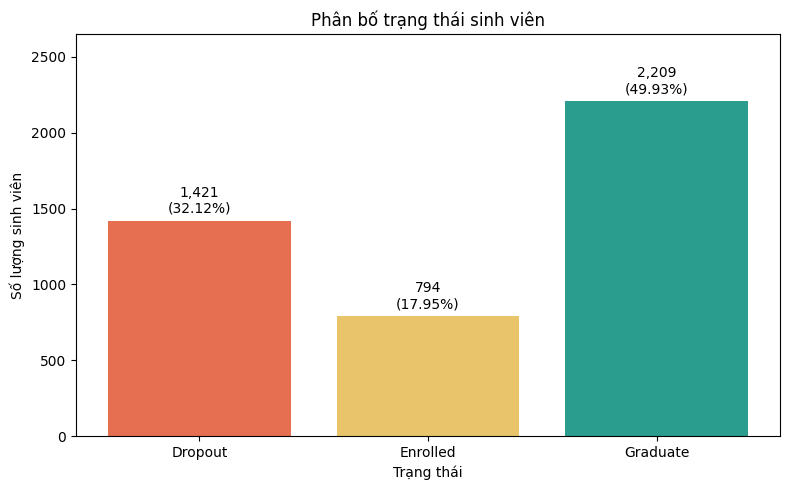

Đã lưu hình tại: c:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\report\figures\01_target_distribution.png


In [22]:
import matplotlib.pyplot as plt

# Tạo thư mục lưu hình
figure_dir = project_dir / "report" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# Cố định thứ tự lớp để dùng thống nhất trong các biểu đồ
class_order = ["Dropout", "Enrolled", "Graduate"]
counts = df["Target"].value_counts().reindex(class_order, fill_value=0)
percentages = counts / len(df) * 100

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    counts.index,
    counts.values,
    color=["#E76F51", "#E9C46A", "#2A9D8F"]
)

for bar, count, percentage in zip(bars, counts, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Phân bố trạng thái sinh viên")
ax.set_xlabel("Trạng thái")
ax.set_ylabel("Số lượng sinh viên")
ax.set_ylim(0, counts.max() * 1.2)

fig.tight_layout()

# Lưu trước khi hiển thị
image_path = figure_dir / "01_target_distribution.png"
fig.savefig(image_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Đã lưu hình tại:", image_path)

### Nhận xét
- Graduate có 2.209 mẫu (49,93%), là lớp có số lượng lớn nhất.
- Dropout có 1.421 mẫu (32,12%).
- Enrolled có 794 mẫu (17,95%), là lớp có số lượng nhỏ nhất.
- Số mẫu Graduate gấp khoảng 2,78 lần Enrolled, cho thấy phân bố
  các lớp không đồng đều.
- Vì vậy, nhóm dự kiến chia dữ liệu có stratification và sử dụng
  Macro-F1 cùng các độ đo theo từng lớp khi đánh giá mô hình.
- Chưa thực hiện lấy mẫu lại hoặc thay đổi phân bố dữ liệu ở bước này.

## 4. Chia dữ liệu phát triển và kiểm tra

### Mục đích
Tạo bộ dữ liệu dùng chung cho bốn thành viên để so sánh mô hình công bằng.

### Cách chia và lý do
- 80% dữ liệu dùng để phát triển mô hình (train và cross-validation).
- 20% dữ liệu giữ riêng làm test, dùng đánh giá sau khi chốt mô hình.
- `stratify` giúp giữ tỷ lệ ba lớp tương đối giống dữ liệu ban đầu.
- `random_state=42` giúp tái lập cách chia trên cùng dữ liệu đầu vào.

Chưa thực hiện encoding, scaling hay lựa chọn đặc trưng.
Các bước học từ dữ liệu sẽ được fit trong từng fold huấn luyện.


In [23]:
from sklearn.model_selection import train_test_split

# Chia khi dữ liệu vẫn ở dạng gốc, chưa encoding hoặc scaling
development_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Target"]
)

# Kiểm tra hai tập không chứa cùng bản ghi theo chỉ số gốc
assert set(development_df.index).isdisjoint(test_df.index)
assert len(development_df) + len(test_df) == len(df)

# Lưu dữ liệu dùng chung cho cả nhóm
processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

development_df.to_csv(
    processed_dir / "development.csv",
    index=False
)
test_df.to_csv(
    processed_dir / "test.csv",
    index=False
)

print("Tập phát triển:", len(development_df), "mẫu")
print("Tập test:", len(test_df), "mẫu")
print("Đã lưu tại:", processed_dir)

# Chỉ kiểm tra tỷ lệ lớp để xác nhận cách chia
split_summary = pd.DataFrame({
    "Toàn bộ (%)": df["Target"].value_counts(normalize=True) * 100,
    "Phát triển (%)": (
        development_df["Target"].value_counts(normalize=True) * 100
    ),
    "Test (%)": test_df["Target"].value_counts(normalize=True) * 100
}).reindex(["Dropout", "Enrolled", "Graduate"]).round(2)

display(split_summary)

Tập phát triển: 3539 mẫu
Tập test: 885 mẫu
Đã lưu tại: c:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\data\processed


,Toàn bộ (%),Phát triển (%),Test (%)
Target,,,
Dropout,32.12,32.13,32.09
Enrolled,17.95,17.94,17.97
Graduate,49.93,49.93,49.94


## 5. Thống kê mô tả các đặc trưng định lượng

### Mục đích
Quan sát phạm vi và phân bố ban đầu của tuổi, điểm và số học phần
trên tập phát triển.

### Cách thực hiện và lý do
Chọn các biến định lượng theo ý nghĩa, không chọn tất cả cột có kiểu số
vì một số cột là mã danh mục.

Thống kê gồm số mẫu, trung bình, độ lệch chuẩn, nhỏ nhất,
các tứ phân vị và lớn nhất.

Chỉ sử dụng tập phát triển; giữ riêng tập test cho đánh giá cuối cùng.
Chưa loại bỏ ngoại lệ hoặc chuẩn hóa dữ liệu ở bước này.